# 밀링 머신 정비 상담 에이전트

작업자가 설비 상태를 말로 물으면, LLM이 학습된 고장 예측 모델(ML/DL)을 직접 호출해서 판정 근거와 조치를 답합니다.

- **LLM 에이전트**: LangChain `bind_tools` + OpenAI Tool Calling (5장)
- **데이터**: AI4I 2020 Predictive Maintenance Dataset (UCI, CC BY 4.0, 밀링 머신 10,000건, 고장 3.4%)
- **ML**: 로지스틱 회귀, 랜덤포레스트 (고장 여부 + 고장 유형 5종)
- **DL**: TensorFlow/Keras 심층 신경망 (Dense + Dropout + EarlyStopping + class_weight)
- **LLM**: LangChain LCEL 체인 (`ChatPromptTemplate | LLM | StrOutputParser`), OpenAI 또는 Ollama(gemma2)
- **환각 방지**: 판정은 코드가 정하고 LLM은 설명만, 출력 판정 자동 검증

| 파일 | 클래스 | 역할 |
|---|---|---|
| `src/data_loader.py` | `AI4IDataLoader` | 데이터 로드 · 파생 변수 · 분할 |
| `src/dl_model.py` | `KerasFailureClassifier` | Keras 심층 신경망 |
| `src/models.py` | `FailurePredictor` | ML/DL 학습 · 평가 · 예측 |
| `src/rule_checker.py` | `FailureRuleChecker` | 고장 기준값 비교 |
| `src/llm_reporter.py` | `MaintenanceReporter` | LangChain 정비 메모 생성 · 판정 검증 |
| `src/agent.py` | `MaintenanceAgent` | LLM 에이전트 · 도구 · 답변 검증 |

## 0. 환경 준비 (Colab)
프로젝트 zip을 올려서 압축을 풉니다. 로컬 실행 시에는 건너뛰세요.

In [1]:
if 'google.colab' in str(get_ipython()):
    from google.colab import files
    uploaded = files.upload()          # 프로젝트 zip 업로드
    zip_name = next(iter(uploaded))
    !unzip -o -q "$zip_name" -d /content/project
    %cd /content/project
    !pip install -q -r requirements.txt

## 1. 데이터 로드 · 파생 변수
고장 원리에 맞춰 온도차(열 방출), 소비 전력(전력 고장), 공구 부하(과부하)를 추가합니다.

In [2]:
from src.data_loader import AI4IDataLoader

loader = AI4IDataLoader()
df = loader.load()
print(loader.summary())
df.head()

{'rows': 10000, 'failure_rate': 0.0339, 'failure_type_counts': {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19}}


,type,air_temp,process_temp,rpm,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF,temp_diff,power,strain
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,6951.590560,0.0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,6826.722724,138.9
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,7749.387543,247.0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,5927.504659,276.5
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,5897.816608,360.0


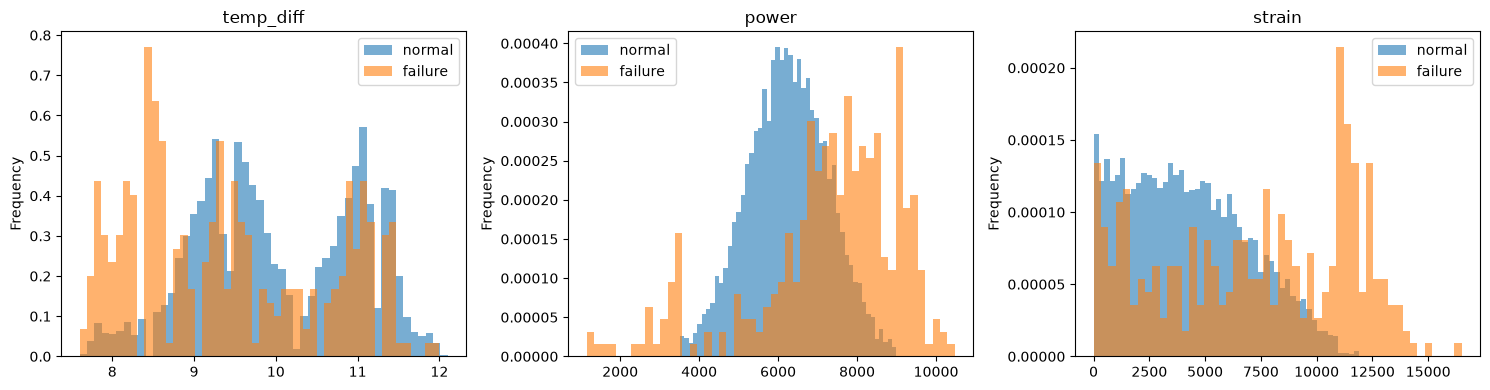

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["temp_diff", "power", "strain"]):
    df[df.machine_failure == 0][col].plot.hist(bins=50, alpha=.6, ax=ax, label="normal", density=True)
    df[df.machine_failure == 1][col].plot.hist(bins=50, alpha=.6, ax=ax, label="failure", density=True)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

## 2. ML/DL 모델 학습 · 비교
고장이 3.4%뿐이라 모두 '정상'이라고 해도 정확도 96.6%가 나옵니다. 그래서 **F1 · 재현율 · ROC-AUC**로 비교합니다.

In [4]:
import pandas as pd
from src.models import FailurePredictor

X_train, X_test, y_train, y_test, yt_train, yt_test = loader.split()
predictor = FailurePredictor().fit(X_train, y_train, yt_train)
metrics = predictor.evaluate(X_test, y_test, yt_test)

pd.DataFrame(metrics["binary"]).T.drop(columns="confusion_matrix")

,accuracy,precision,recall,f1,roc_auc
LogisticRegression,0.8585,0.179104,0.882353,0.297767,0.938505
RandomForest,0.99,0.961538,0.735294,0.833333,0.97917
Keras DNN (Deep Learning),0.978,0.671429,0.691176,0.681159,0.978619


### Keras 심층 신경망 학습 곡선

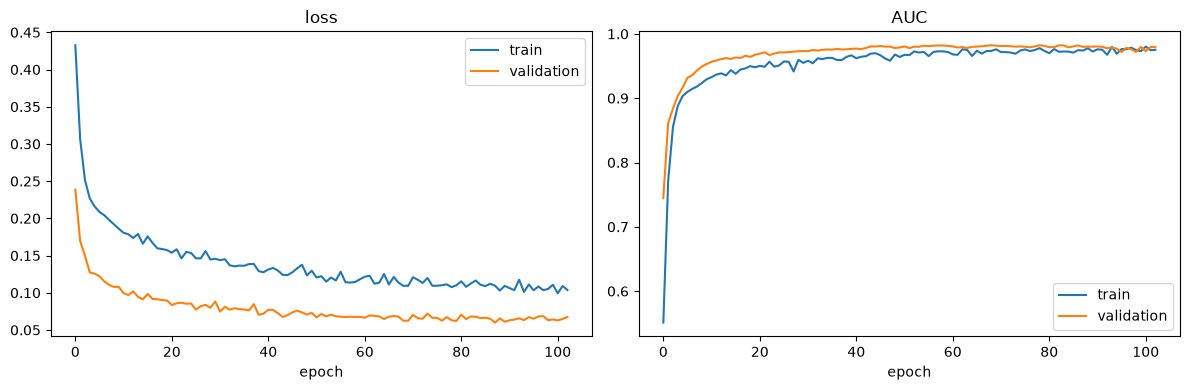

학습 epoch 수: 103


In [5]:
hist = predictor.dl_history()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["loss"], label="train"); axes[0].plot(hist["val_loss"], label="validation")
axes[0].set_title("loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist["auc"], label="train"); axes[1].plot(hist["val_auc"], label="validation")
axes[1].set_title("AUC"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()
print("학습 epoch 수:", len(hist["loss"]))

### 고장 유형별 성능 · 특성 중요도

In [6]:
print("대표 모델:", metrics["best_model"])
pd.DataFrame(metrics["failure_types"]).T

대표 모델: RandomForest


,support,recall,precision,f1
TWF,10.0,0.000000,0.000000,0.000000
HDF,29.0,0.758621,0.916667,0.830189
PWF,13.0,1.000000,1.000000,1.000000
OSF,16.0,0.937500,1.000000,0.967742
RNF,4.0,0.000000,0.000000,0.000000


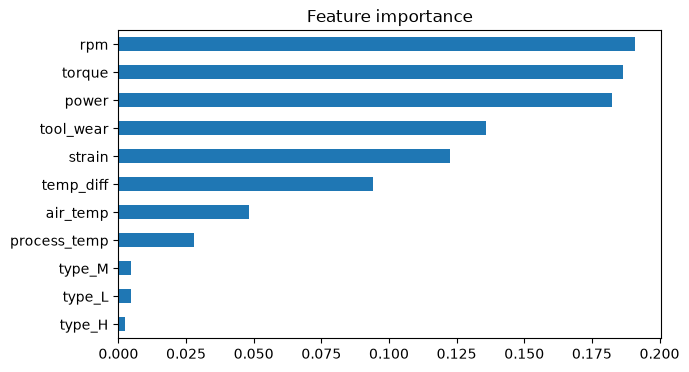

WindowsPath('models/predictor.joblib')

In [7]:
predictor.feature_importance().iloc[::-1].plot.barh(figsize=(7, 4), title="Feature importance")
plt.show()
predictor.save()

## 3. 단일 설비 진단 + 기준값 비교

In [8]:
from src.rule_checker import FailureRuleChecker

K = 273.15
X_row = AI4IDataLoader.make_single("L", air_temp=25.9 + K, process_temp=36.4 + K,
                                   rpm=1350, torque=60.0, tool_wear=210)
sensor = X_row.iloc[0].to_dict()
pred = predictor.predict_one(X_row)
findings = FailureRuleChecker().check(sensor)

print(pred)
for f in findings:
    print("기준 초과" if f["triggered"] else "정상", "|", f["name"], "|", f["detail"])

{'model': 'RandomForest', 'failure_probability': 0.9466666666666667, 'failure_predicted': True, 'failure_type_probabilities': {'TWF': 0.0, 'HDF': 0.0, 'PWF': 0.023333333333333334, 'OSF': 0.9366666666666666, 'RNF': 0.0}}
기준 초과 | 공구 마모 | 210분 사용 (위험 기준: 200~240분)
정상 | 열 방출 불량 | 10.5°C / 1350rpm (위험 기준: 8.6°C 미만 + 1380rpm 미만)
정상 | 전력 이상 | 8,482W (위험 기준: 3,500W 미만 / 9,000W 초과)
기준 초과 | 과부하 | 부하 12,600 (위험 기준: L등급 11,000 초과)


## 4. LangChain 정비 메모 생성
- 판정(정상/주의/위험)은 코드가 정하고, LLM은 근거와 조치만 씁니다.
- LLM이 판정을 다르게 쓰면 `verify_verdict()`가 자동으로 바로잡습니다.
- `provider="ollama"`이면 로컬 gemma2(무료), `"openai"`이면 OpenAI API를 씁니다.

In [9]:
import os, getpass
from IPython.display import Markdown
from src.llm_reporter import MaintenanceReporter

PROVIDER = "openai"   # 로컬에 Ollama(gemma2)가 있으면 "ollama"로 바꿔도 됨 (무료)
if PROVIDER == "openai" and not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key: ")

reporter = MaintenanceReporter(provider=PROVIDER)
print("체인:", reporter.get_chain())
Markdown(reporter.generate(sensor, pred, findings))

체인: first=ChatPromptTemplate(input_variables=['diagnosis'], input_types={}, partial_variables={}, messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=[], input_types={}, partial_variables={}, template='너는 밀링 머신을 15년째 관리해 온 설비 보전 담당자다.\n교대 근무자에게 넘기는 점검 메모를 쓴다. 읽는 사람은 바쁜 현장 작업자다.\n\n반드시 지킬 것:\n- 판정은 입력의 "판정" 값을 그대로 쓴다. 절대 바꾸지 않는다.\n- "원인"에는 "기준_초과_항목"에 있는 것만 쓴다. "기준_이내_항목"은 원인으로 쓰지 않는다.\n- 기준_초과_항목이 없으면 원인은 "기준 초과 항목 없음" 한 줄만 쓴다.\n- 판정이 정상이면 조치는 "현 상태로 운전 유지, 정기 점검 주기대로 확인" 수준으로 1~2줄만 쓴다.\n- 원인 한 줄마다 "현재값 → 위험기준" 형식으로 수치를 함께 쓴다. (예: 과부하 — 부하 12,600 → L등급 11,000 초과)\n- 조치는 원인과 연결해서 구체적으로 쓴다. (예: 공구 교체, 토크 설정 낮춤)\n- 입력 JSON의 키 이름(기준_초과_항목 등)을 그대로 쓰지 않는다.\n- 주어진 수치만 근거로 쓴다. 부품명, 과거 이력처럼 주어지지 않은 정보는 만들지 않는다.\n\n문체:\n- 인사말, 맺음말, 감탄, 이모지, "~해 보세요" 같은 표현 금지.\n- 개조식(~함, ~필요, ~권장)으로 짧게. 전체 12줄 이내. 수치에는 단위를 붙인다.\n\n형식 (그대로 따를 것, 제목 크기 키우지 말 것):\n**판정: (입력의 판정)** — 한 줄 근거\n\n**원인**\n- ...\n\n**조치** (급한 순서)\n1. ...\n\n**다음 점검 때 확인**\n- ...\n'), additional_kwargs={}), HumanMes

**판정: 위험** — 고장 확률 94.7%

**원인**
- 공구 마모 — 210분 사용 → 200~240분
- 과부하 — 부하 12,600 → L등급 11,000 초과

**조치** (급한 순서)
1. 공구 교체
2. 부하 조정

**다음 점검 때 확인**
- 공구 사용 시간 및 부하 상태

## 5. LLM 정비 상담 에이전트 (핵심)
작업자의 질문을 LLM이 이해하고, 학습된 모델을 도구로 호출해서 답합니다.
- `diagnose`: 고장 확률 · 판정 · 기준 초과 항목 계산
- `suggest_adjustments`: 공구 교체 · 토크 낮추기 · 회전수 조정의 효과를 모델로 계산
- 답변 검증: 도구 결과에 없는 수치 감지, 가정한 입력값 자동 표시

Tool Calling이 필요해서 OpenAI 키가 있어야 합니다.

In [10]:
from src.agent import MaintenanceAgent

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key: ")

agent = MaintenanceAgent(predictor, provider="openai")
history = []
for q in ["L등급 제품인데 토크 60Nm, 공구 210분 썼어. 계속 돌려도 돼?",
          "그럼 어떻게 하면 돼? 공구 교체 말고 다른 방법도 있어?",
          "토크만 40으로 낮추면?"]:
    answer, trace, history = agent.run(history, q)
    print("작업자:", q)
    print("호출한 도구:", [(t["tool"], t["args"]) for t in trace])
    print(answer)
    print("근거 없는 수치:", MaintenanceAgent.check_numbers(answer, trace) or "없음")
    print("-" * 60)

작업자: L등급 제품인데 토크 60Nm, 공구 210분 썼어. 계속 돌려도 돼?
호출한 도구: [('diagnose', {'product_type': 'L', 'torque': 60, 'tool_wear_min': 210})]
위험, 고장 확률 86.0%.  
- 공구 사용 시간이 210분으로 기준 초과 (200~240분).  
- 전력 소비가 9,425W로 기준 초과 (3,500W 미만 / 9,000W 초과).  
- 과부하가 발생하고 있음 (부하 12,600, L등급 11,000 초과).  

즉시 작업 중단, 공구 교체 및 토크 조정 필요.  
온도와 회전수 확인 후 재진단 권장.  
가정: 주변 온도 26.9°C, 가공 온도 36.9°C, 회전수 1500rpm으로 가정.
근거 없는 수치: 없음
------------------------------------------------------------


작업자: 그럼 어떻게 하면 돼? 공구 교체 말고 다른 방법도 있어?
호출한 도구: [('suggest_adjustments', {'product_type': 'L', 'torque': 60, 'tool_wear_min': 210})]
토크를 60Nm에서 50Nm로 낮추면 주의, 고장 확률 8.7%.  
- 공구 교체는 여전히 위험 (고장 확률 56.0%).  
- 회전수 조정만으로는 안전 구간을 찾지 못함.  
- 공구 사용 시간이 200~240분 구간이라 공구 마모 위험은 공구 교체로만 해소됨.  

토크를 낮추고 작업 진행 가능, 그러나 공구 교체를 권장.  
가정: 주변 온도 26.9°C, 가공 온도 36.9°C, 회전수 1500rpm으로 가정.
근거 없는 수치: 없음
------------------------------------------------------------


작업자: 토크만 40으로 낮추면?
호출한 도구: [('diagnose', {'product_type': 'L', 'torque': 40, 'tool_wear_min': 210})]
주의, 고장 확률 8.3%.  
- 토크를 40Nm으로 낮추면 공구 마모 위험은 여전히 존재 (15.3%).  
- 공구 사용 시간이 210분으로 기준 초과 (200~240분).  

작업 진행 가능하나, 공구 교체를 권장.  
가정: 주변 온도 26.9°C, 가공 온도 36.9°C, 회전수 1500rpm으로 가정.
근거 없는 수치: 없음
------------------------------------------------------------


## 6. 시연
- 로컬: `streamlit run app.py`
- 배포: Streamlit Community Cloud (README 참고)